# Seasonal Demand Analysis: Radiology Services
**Objective:** Use 24 months of imaging volume to identify seasonal surges (late July and early December) and translate them into radiographer staffing and leave-planning recommendations.

> **Data note:** The dataset in `data/` is **synthetic** and mirrors the seasonal pattern observed in practice. It contains no patient information. The code works unchanged on a real anonymized file with the same columns:
> `exam_id, exam_date, exam_type, patient_category, department_or_body_part`.

**Contents:** 1) Cleaning & feature engineering, 2) EDA, 3) Visualization, 4) Operational recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
DATA_PATH = "../data/anonymized_radiology_volume.csv"
VISUALS = "../visuals/"


## 1. Data Cleaning & Feature Engineering

In [2]:
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
df.head()

Raw shape: (26075, 5)


,exam_id,exam_date,exam_type,patient_category,department_or_body_part
0,EX000016,2023-01-01,General Radiography,Inpatient,Spine
1,EX000015,2023-01-01,General Radiography,Inpatient,Limbs
2,EX000013,2023-01-01,General Radiography,Inpatient,Spine
3,EX000014,2023-01-01,General Radiography,Inpatient,Limbs
4,EX000019,2023-01-01,Ultrasound,Outpatient,Abdominal


In [3]:
# Quick audit: missing values and duplicates
print("Missing values per column:")
print(df.isna().sum(), "\n")
print("Exact duplicate rows:", df.duplicated().sum())
print("\nRaw exam_type values:")
print(df["exam_type"].value_counts())

Missing values per column:
exam_id                      0
exam_date                    0
exam_type                    0
patient_category           261
department_or_body_part    785
dtype: int64 

Exact duplicate rows: 129

Raw exam_type values:
exam_type
General Radiography    15722
Ultrasound              9312
xray                     148
General Radiology        137
X-ray                    135
general radiography      132
Gen. Radiography         126
U/S                      108
ULTRASOUND                88
ultrasound                86
Ultra sound               81
Name: count, dtype: int64


Cleaning steps:
1. Remove exact duplicate rows
2. Standardize `exam_type` spelling (X-ray variants map to *General Radiography*, U/S variants to *Ultrasound*)
3. Fill missing categorical values with `"Unknown"` rather than dropping exams, because every exam still counts toward workload
4. Parse dates and extract time features

In [4]:
df = df.drop_duplicates().copy()

def standardize_exam_type(x):
    if pd.isna(x):
        return "Unknown"
    s = str(x).strip().lower().replace(".", "").replace(" ", "").replace("-", "")
    if s in {"xray", "generalradiography", "genradiography", "generalradiology"}:
        return "General Radiography"
    if s in {"ultrasound", "u/s", "us"}:
        return "Ultrasound"
    return "Other"

df["exam_type"] = df["exam_type"].apply(standardize_exam_type)
df["patient_category"] = df["patient_category"].fillna("Unknown").str.strip().str.title()
df["department_or_body_part"] = df["department_or_body_part"].fillna("Unknown").str.strip()

# Time features
df["exam_date"] = pd.to_datetime(df["exam_date"])
df["Year"] = df["exam_date"].dt.year
df["Month"] = df["exam_date"].dt.month
df["Year_Month"] = df["exam_date"].dt.to_period("M").astype(str)
df["Week_of_Year"] = df["exam_date"].dt.isocalendar().week.astype(int)
df["Day_of_Week"] = df["exam_date"].dt.day_name()

print("Clean shape:", df.shape)
print(df["exam_type"].value_counts())
df.head()

Clean shape: (25946, 10)
exam_type
General Radiography    16317
Ultrasound              9629
Name: count, dtype: int64


,exam_id,exam_date,exam_type,patient_category,department_or_body_part,Year,Month,Year_Month,Week_of_Year,Day_of_Week
0,EX000016,2023-01-01,General Radiography,Inpatient,Spine,2023,1,2023-01,52,Sunday
1,EX000015,2023-01-01,General Radiography,Inpatient,Limbs,2023,1,2023-01,52,Sunday
2,EX000013,2023-01-01,General Radiography,Inpatient,Spine,2023,1,2023-01,52,Sunday
3,EX000014,2023-01-01,General Radiography,Inpatient,Limbs,2023,1,2023-01,52,Sunday
4,EX000019,2023-01-01,Ultrasound,Outpatient,Abdominal,2023,1,2023-01,52,Sunday


## 2. Exploratory Data Analysis

In [5]:
total = len(df)
print(f"Total examinations over the period: {total:,}")
print(f"Period: {df.exam_date.min().date()} to {df.exam_date.max().date()}")

# Daily counts (include zero-days so averages are correct)
daily = (df.groupby("exam_date").size()
           .reindex(pd.date_range(df.exam_date.min(), df.exam_date.max()), fill_value=0)
           .rename("exams").rename_axis("date").reset_index())
daily["Month"] = daily["date"].dt.month
daily["Year_Month"] = daily["date"].dt.to_period("M").astype(str)
daily["Day_of_Week"] = daily["date"].dt.day_name()
print(f"Average daily volume: {daily.exams.mean():.1f} exams/day")

Total examinations over the period: 25,946
Period: 2023-01-01 to 2024-12-31
Average daily volume: 35.5 exams/day


In [6]:
# Monthly totals and average daily volume per month
monthly = (daily.groupby("Year_Month")["exams"].agg(total="sum", avg_per_day="mean").round(1))
monthly

,total,avg_per_day
Year_Month,,
2023-01,1107,35.7
2023-02,945,33.8
2023-03,1073,34.6
2023-04,1017,33.9
2023-05,1151,37.1
2023-06,1019,34.0
2023-07,1201,38.7
2023-08,1142,36.8
2023-09,1042,34.7


In [7]:
# Weekly volume and statistical spikes (z-score > 1.5 = unusually busy week)
weekly = (daily.set_index("date")["exams"].resample("W-SUN").sum().rename("exams").to_frame())
weekly = weekly.iloc[1:-1]  # drop partial first/last weeks so they don't distort the analysis
weekly["z_score"] = (weekly["exams"] - weekly["exams"].mean()) / weekly["exams"].std()
spikes = weekly[weekly["z_score"] > 1.5]
print(f"Average weekly volume: {weekly.exams.mean():.0f}")
print(f"Weeks flagged as spikes (z > 1.5): {len(spikes)}")
spikes

Average weekly volume: 248
Weeks flagged as spikes (z > 1.5): 8


,exams,z_score
date,,
2023-07-30,353,3.600562
2023-08-06,293,1.534205
2023-12-03,331,2.842898
2023-12-10,367,4.082713
2024-07-28,342,3.221730
2024-08-04,299,1.740840
2024-12-08,352,3.566123
2024-12-15,311,2.154112


In [8]:
# Which modality drives the surge?
by_type_month = df.groupby(["Year_Month", "exam_type"]).size().unstack(fill_value=0)
print(by_type_month.describe().round(1))

# Share of volume by modality
print((df["exam_type"].value_counts(normalize=True) * 100).round(1))

exam_type  General Radiography  Ultrasound
count                     24.0        24.0
mean                     679.9       401.2
std                       64.1        28.3
min                      605.0       329.0
25%                      637.5       389.2
50%                      666.5       403.0
75%                      719.5       416.2
max                      833.0       448.0
exam_type
General Radiography    62.9
Ultrasound             37.1
Name: proportion, dtype: float64


## 3. Data Visualization

### 3.1 Weekly demand over 24 months, with peak windows highlighted

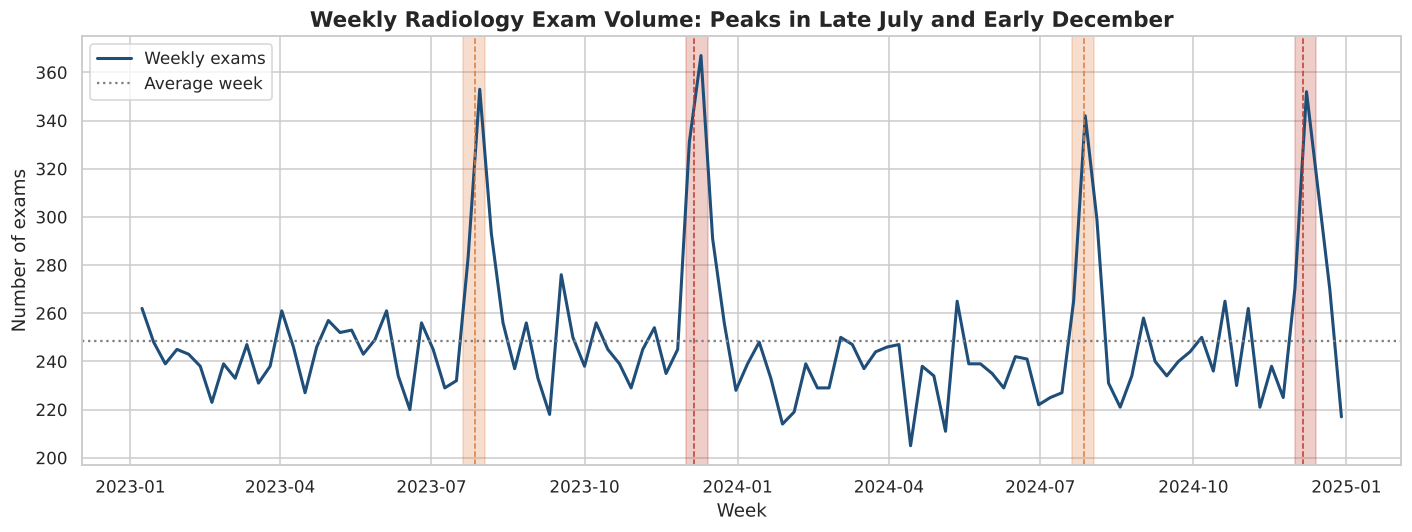

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(weekly.index, weekly["exams"], color="#1f4e79", lw=2, label="Weekly exams")

# Shade late-July and early-December windows each year
for year in sorted(df["Year"].unique()):
    ax.axvspan(pd.Timestamp(year, 7, 20), pd.Timestamp(year, 8, 2), color="#e07b39", alpha=0.25)
    ax.axvspan(pd.Timestamp(year, 12, 1), pd.Timestamp(year, 12, 14), color="#c0392b", alpha=0.25)
    ax.axvline(pd.Timestamp(year, 7, 27), color="#e07b39", ls="--", lw=1)
    ax.axvline(pd.Timestamp(year, 12, 6), color="#c0392b", ls="--", lw=1)

ax.axhline(weekly["exams"].mean(), color="grey", ls=":", label="Average week")
ax.set_title("Weekly Radiology Exam Volume: Peaks in Late July and Early December", fontsize=14, weight="bold")
ax.set_xlabel("Week")
ax.set_ylabel("Number of exams")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(VISUALS + "monthly_demand_trends.png", dpi=200)
plt.show()

### 3.2 Stacked bar: General Radiography vs Ultrasound by month

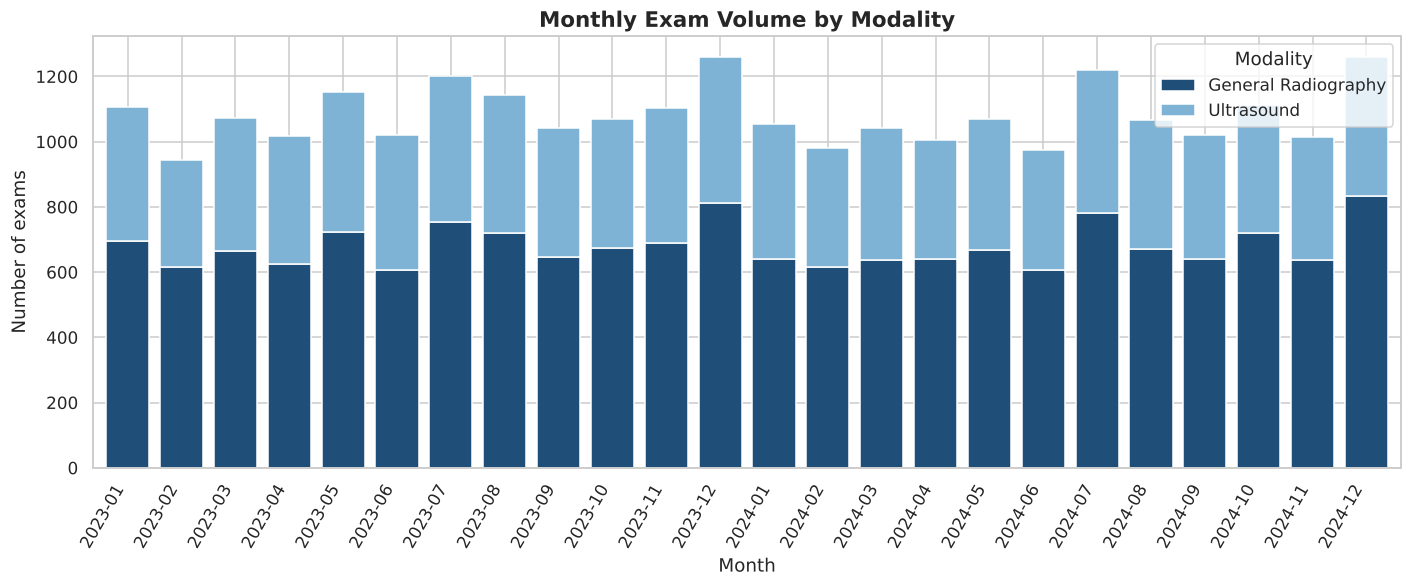

In [10]:
plot_df = by_type_month[[c for c in ["General Radiography", "Ultrasound"] if c in by_type_month.columns]]
ax = plot_df.plot(kind="bar", stacked=True, figsize=(13, 5.5), color=["#1f4e79", "#7fb3d5"], width=0.8)
ax.set_title("Monthly Exam Volume by Modality", fontsize=14, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of exams")
ax.legend(title="Modality")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(VISUALS + "modality_breakdown.png", dpi=200)
plt.show()

### 3.3 Heatmap: average daily exams by month and day of week

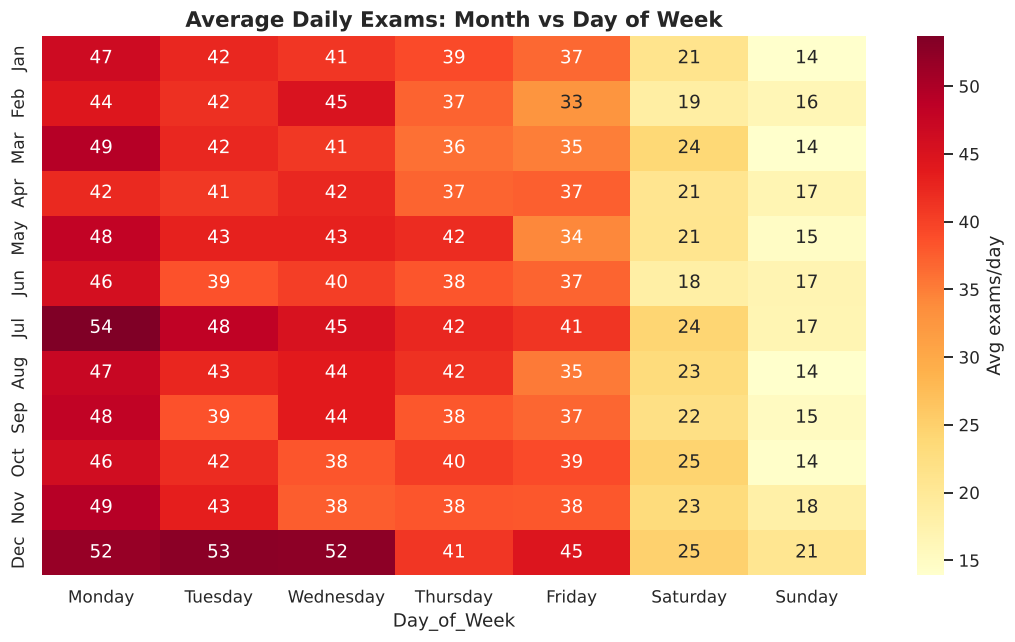

In [11]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (daily.groupby(["Month", "Day_of_Week"])["exams"].mean()
             .unstack()[order].round(1))
heat.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Avg exams/day"})
plt.title("Average Daily Exams: Month vs Day of Week", fontsize=14, weight="bold")
plt.ylabel("")
plt.tight_layout()
plt.savefig(VISUALS + "heatmap_month_weekday.png", dpi=200)
plt.show()

## 4. Operational Recommendations (Staffing Model)

**Method:** Weeks overlapping the late-July window (Jul 20 - Aug 2) and the early-December window (Dec 1 - Dec 14) are labelled *peak*. All other weeks are *baseline*. We compare the average weekly volume of each group.

In [12]:
def label_week(week_end):
    start = week_end - pd.Timedelta(days=6)
    for y in (week_end.year, start.year):
        for a, b in [((7, 20), (8, 2)), ((12, 1), (12, 14))]:
            if start <= pd.Timestamp(y, *b) and week_end >= pd.Timestamp(y, *a):
                return "Peak - Late July" if a == (7, 20) else "Peak - Early December"
    return "Baseline"

w = weekly.copy()
w["period"] = [label_week(d) for d in w.index]

summary = w.groupby("period")["exams"].agg(weeks="count", avg_weekly="mean").round(1)
baseline = summary.loc["Baseline", "avg_weekly"]
summary["pct_increase_vs_baseline"] = ((summary["avg_weekly"] / baseline - 1) * 100).round(1)
summary

,weeks,avg_weekly,pct_increase_vs_baseline
period,,,
Baseline,92,240.0,0.0
Peak - Early December,6,320.3,33.5
Peak - Late July,6,305.8,27.4


In [13]:
# Which modality drives the surge? Compare average weekly volume peak vs baseline
d = df.copy()
wk = d.groupby([pd.Grouper(key="exam_date", freq="W-SUN"), "exam_type"]).size().unstack(fill_value=0)
wk = wk.loc[weekly.index.intersection(wk.index)]
wk["period"] = [label_week(x) for x in wk.index]
mod = wk.groupby("period")[["General Radiography", "Ultrasound"]].mean()
mod_pct = ((mod / mod.loc["Baseline"] - 1) * 100).round(1)
print("Average weekly exams by modality:"); display(mod.round(1))
print("% increase vs baseline:"); display(mod_pct)

Average weekly exams by modality:


exam_type,General Radiography,Ultrasound
period,,
Baseline,149.8,90.3
Peak - Early December,214.2,106.2
Peak - Late July,198.5,107.3


% increase vs baseline:


exam_type,General Radiography,Ultrasound
period,,
Baseline,0.0,0.0
Peak - Early December,43.0,17.6
Peak - Late July,32.6,18.9


In [14]:
# Simple staffing model (ASSUMPTIONS: adjust to your department's real figures)
EXAMS_PER_RADIOGRAPHER_PER_DAY = 12   # assumed productive capacity
WORKING_DAYS_PER_WEEK = 6             # department operating days

def radiographers_needed(weekly_exams):
    return weekly_exams / (EXAMS_PER_RADIOGRAPHER_PER_DAY * WORKING_DAYS_PER_WEEK)

staff = summary[["avg_weekly", "pct_increase_vs_baseline"]].copy()
staff["radiographers_needed"] = radiographers_needed(staff["avg_weekly"]).round(1)
staff["extra_vs_baseline"] = (staff["radiographers_needed"] - staff.loc["Baseline", "radiographers_needed"]).round(1)
staff

,avg_weekly,pct_increase_vs_baseline,radiographers_needed,extra_vs_baseline
period,,,,
Baseline,240.0,0.0,3.3,0.0
Peak - Early December,320.3,33.5,4.4,1.1
Peak - Late July,305.8,27.4,4.2,0.9


### Draft recommendations (for the Director of Allied Health Sciences)
*Replace the figures below with the output from your real data.*

1. **Leave-restriction windows:** Limit annual leave for radiographers during **Jul 20 - Aug 2** and **Dec 1 - Dec 14**, with leave approvals front-loaded in the preceding months.
2. **Shift adjustments in peak weeks:** Add an extended or overlapping shift (e.g. a mid-day shift 10:00-18:00) on Mondays and Tuesdays, which the heatmap shows as the busiest days.
3. **Modality-specific cover:** Prioritize extra capacity for the modality showing the larger percentage rise (see the modality table above).
4. **Float / on-call pool:** Pre-arrange on-call or float radiographers equal to the "extra vs baseline" figure from the staffing table.
5. **Review annually:** Re-run this notebook each year to confirm the pattern still holds and adjust the windows.

**Limitations:** Only 24 months of data (two peaks per season). Capacity figures are assumptions. Demand does not capture equipment downtime or staff sickness.